# Day 03 – Missing Value Imputation
## Holistic Data Preparer | Fintech – Customer Credit Risk Prediction

## 1. Imports and project paths

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer, MissingIndicator, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
cwd = Path.cwd()
PROJECT_ROOT = cwd if (cwd / "data").exists() else cwd.parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
REPORTS_DIR = PROJECT_ROOT / "reports"
for folder in [RAW_DIR, INTERIM_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT.resolve())

Project root: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\notebooks


## 2. Load the same Customer Credit Risk dataset

In [2]:
EXPECTED = ["customer_id","age","gender","region","education_level","employment_type",
"annual_income","loan_amount","loan_purpose","credit_score","repayment_history",
"transaction_count","spending_ratio","join_date","default_flag"]
source_path = RAW_DIR / "customer_credit_risk.csv"
valid_source = False
if source_path.exists():
    preview = pd.read_csv(source_path, nrows=5)
    valid_source = set(EXPECTED).issubset(preview.columns)

if valid_source:
    df = pd.read_csv(source_path)
    DATA_SOURCE = f"User-provided source: {source_path.name}"
else:
    rng = np.random.default_rng(RANDOM_STATE)
    n = 1000
    df = pd.DataFrame({
        "customer_id": np.arange(100001,100001+n),
        "age": rng.integers(21,66,n).astype(float),
        "gender": rng.choice(["Female","Male","Other"],n),
        "region": rng.choice(["North","South","East","West"],n),
        "education_level": rng.choice(["High School","Graduate","Postgraduate"],n),
        "employment_type": rng.choice(["Salaried","Self-employed","Business","Unemployed"],n),
        "annual_income": rng.normal(650000,220000,n).clip(120000,1800000),
        "loan_amount": rng.normal(250000,110000,n).clip(20000,900000),
        "loan_purpose": rng.choice(["Home","Education","Personal","Vehicle","Business"],n),
        "credit_score": rng.normal(690,75,n).clip(300,900),
        "repayment_history": rng.choice(["Good","Average","Poor"],n,p=[.60,.27,.13]),
        "transaction_count": rng.poisson(35,n).astype(float),
        "spending_ratio": rng.beta(2.2,5,n),
        "join_date": pd.date_range("2021-01-01",periods=n,freq="D").astype(str),
        "default_flag": rng.choice([0,1],n,p=[.82,.18])
    })
    for col, frac in {"age":.05,"annual_income":.08,"loan_amount":.04,
        "credit_score":.07,"gender":.03,"region":.04,"employment_type":.06,
        "repayment_history":.05,"spending_ratio":.05,"join_date":.02}.items():
        idx = rng.choice(df.index,size=int(n*frac),replace=False)
        df.loc[idx,col] = np.nan
    DATA_SOURCE = "Synthetic demonstration data (no compatible source CSV found)"
print(DATA_SOURCE, "| shape:", df.shape)
display(df.head())

Synthetic demonstration data (no compatible source CSV found) | shape: (1000, 15)


,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,repayment_history,transaction_count,spending_ratio,join_date,default_flag
0,100001,25.0,Other,West,Postgraduate,Self-employed,567257.078077,203652.899789,Personal,NaN,Good,35.0,0.245852,2021-01-01,0
1,100002,55.0,Other,North,Postgraduate,Unemployed,549222.003633,357645.215003,Vehicle,621.651638,Average,34.0,0.487278,2021-01-02,0
2,100003,50.0,Male,NaN,Postgraduate,Salaried,819172.491746,190787.099515,Education,819.857156,Good,29.0,0.272024,2021-01-03,0
3,100004,40.0,Other,South,Postgraduate,Self-employed,830202.917161,245846.946211,Home,730.222607,Average,40.0,0.411828,2021-01-04,1
4,100005,40.0,Female,West,Postgraduate,NaN,532280.826257,76055.814034,Personal,661.062092,Good,31.0,0.188984,2021-01-05,0


## 3. Create a working copy – raw data stays unchanged

In [3]:
working_df = df.copy(deep=True)
input_path = INTERIM_DIR / "customer_credit_risk_day03_input.csv"
working_df.to_csv(input_path,index=False)
print("Saved input snapshot:",input_path)

Saved input snapshot: c:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\notebooks\data\interim\customer_credit_risk_day03_input.csv


## 4. Missing-value profile

In [4]:
missing_summary = pd.DataFrame({
    "missing_count":working_df.isna().sum(),
    "missing_percentage":(working_df.isna().mean()*100).round(2),
    "data_type":working_df.dtypes.astype(str)
}).sort_values("missing_percentage",ascending=False)
display(missing_summary)

,missing_count,missing_percentage,data_type
annual_income,80,8.0,float64
credit_score,70,7.0,float64
employment_type,60,6.0,object
repayment_history,50,5.0,object
spending_ratio,50,5.0,float64
age,50,5.0,float64
region,40,4.0,object
loan_amount,40,4.0,float64
gender,30,3.0,object
join_date,20,2.0,object


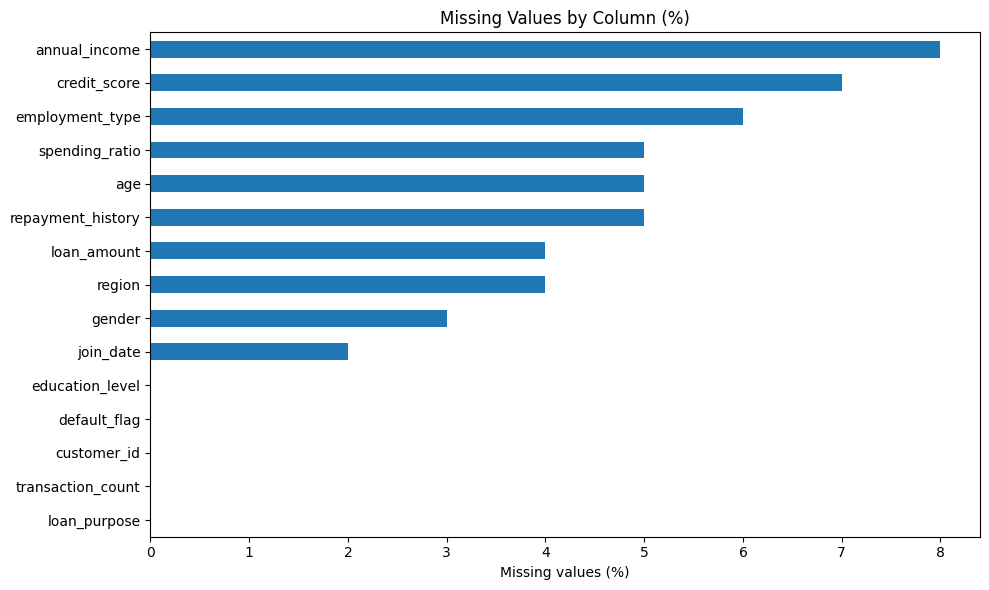

In [5]:
missing_summary["missing_percentage"].sort_values().plot(
    kind="barh",figsize=(10,6),title="Missing Values by Column (%)")
plt.xlabel("Missing values (%)")
plt.tight_layout()
plt.show()

## 5. Identify feature types and protect ID/target

In [6]:
TARGET = "default_flag"
ID_COLUMNS = ["customer_id"]
DATE_COLUMNS = ["join_date"]
numeric_features = [c for c in working_df.select_dtypes(include="number").columns
                    if c not in ID_COLUMNS + [TARGET]]
categorical_features = [c for c in working_df.select_dtypes(include=["object","category","bool"]).columns
                        if c not in DATE_COLUMNS]
print("Numerical features:",numeric_features)
print("Categorical features:",categorical_features)
print("Missing target labels:",int(working_df[TARGET].isna().sum()))

Numerical features: ['age', 'annual_income', 'loan_amount', 'credit_score', 'transaction_count', 'spending_ratio']
Categorical features: ['gender', 'region', 'education_level', 'employment_type', 'loan_purpose', 'repayment_history']
Missing target labels: 0


Do not fill an unknown `default_flag` with 0 or 1: this fabricates a label. Investigate or exclude missing-target rows from supervised training. `customer_id` is an identifier, not a measurement. Date values are left untouched in this notebook.

## 6. Simple imputation – mean, median, and mode

In [8]:
numeric_missing = [c for c in numeric_features if working_df[c].isna().any()]
if numeric_missing:
    mean_imp = SimpleImputer(strategy="mean")
    median_imp = SimpleImputer(strategy="median")
    mean_data = pd.DataFrame(mean_imp.fit_transform(working_df[numeric_missing]),
        columns=numeric_missing,index=working_df.index)
    median_data = pd.DataFrame(median_imp.fit_transform(working_df[numeric_missing]),
        columns=numeric_missing,index=working_df.index)
    display(pd.DataFrame({
        "feature":numeric_missing,
        "missing_before":[int(working_df[c].isna().sum()) for c in numeric_missing],
        "mean_missing_after":[int(mean_data[c].isna().sum()) for c in numeric_missing],
        "median_missing_after":[int(median_data[c].isna().sum()) for c in numeric_missing],
        "mean_value":mean_imp.statistics_,
        "median_value":median_imp.statistics_
    }))
else:
    print("No missing numerical values.")

,feature,missing_before,mean_missing_after,median_missing_after,mean_value,median_value
0,age,50,0,0,43.002105,43.000000
1,annual_income,80,0,0,660798.747633,658337.320380
2,loan_amount,40,0,0,249798.512036,246683.696185
3,credit_score,70,0,0,694.649864,695.653979
4,spending_ratio,50,0,0,0.302513,0.281860


In [9]:
categorical_missing = [c for c in categorical_features if working_df[c].isna().any()]
if categorical_missing:
    mode_imp = SimpleImputer(strategy="most_frequent")
    mode_data = pd.DataFrame(mode_imp.fit_transform(working_df[categorical_missing]),
        columns=categorical_missing,index=working_df.index)
    display(pd.DataFrame({"feature":categorical_missing,
        "mode_used":mode_imp.statistics_,
        "missing_after":[int(mode_data[c].isna().sum()) for c in categorical_missing]}))
else:
    print("No missing categorical values.")

,feature,mode_used,missing_after
0,gender,Female,0
1,region,South,0
2,employment_type,Self-employed,0
3,repayment_history,Good,0


## 7. Missingness indicators

In [10]:
indicator_features = [c for c in numeric_features+categorical_features if working_df[c].isna().any()]
if indicator_features:
    indicator = MissingIndicator(features="all",error_on_new=False)
    flags = indicator.fit_transform(working_df[indicator_features])
    indicator_df = pd.DataFrame(flags.astype(int),
        columns=[c+"_was_missing" for c in indicator_features],index=working_df.index)
    display(indicator_df.head())
else:
    indicator_df = pd.DataFrame(index=working_df.index)
    print("No eligible missing values.")

,age_was_missing,annual_income_was_missing,loan_amount_was_missing,credit_score_was_missing,spending_ratio_was_missing,gender_was_missing,region_was_missing,employment_type_was_missing,repayment_history_was_missing
0,0,0,0,1,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0
3,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,1,0


## 8. Random-sample imputation

In [11]:
def random_sample_impute(series, random_state=42):
    result = series.copy()
    observed = result.dropna()
    missing_n = int(result.isna().sum())
    if missing_n == 0 or observed.empty:
        return result
    sampled = observed.sample(n=missing_n,replace=True,random_state=random_state).to_numpy()
    result.loc[result.isna()] = sampled
    return result

random_demo = working_df.copy()
random_cols = [c for c in numeric_features+categorical_features if working_df[c].isna().any()]
for col in random_cols:
    random_demo[col] = random_sample_impute(random_demo[col],RANDOM_STATE)
display(pd.DataFrame({"feature":random_cols,
    "missing_before":[int(working_df[c].isna().sum()) for c in random_cols],
    "missing_after":[int(random_demo[c].isna().sum()) for c in random_cols]}))

,feature,missing_before,missing_after
0,age,50,0
1,annual_income,80,0
2,loan_amount,40,0
3,credit_score,70,0
4,spending_ratio,50,0
5,gender,30,0
6,region,40,0
7,employment_type,60,0
8,repayment_history,50,0


## 9. KNN imputation – numerical features

In [12]:
if numeric_features and working_df[numeric_features].isna().any().any():
    knn_imp = KNNImputer(n_neighbors=5,weights="distance")
    knn_values = knn_imp.fit_transform(working_df[numeric_features])
    knn_data = pd.DataFrame(knn_values,columns=numeric_features,index=working_df.index)
    print("KNN missing values remaining:",int(knn_data.isna().sum().sum()))
    display(knn_data.head())
else:
    knn_data = working_df[numeric_features].copy()
    print("KNN imputation not required.")

KNN missing values remaining: 0


,age,annual_income,loan_amount,credit_score,transaction_count,spending_ratio
0,25.0,567257.078077,203652.899789,553.510367,35.0,0.245852
1,55.0,549222.003633,357645.215003,621.651638,34.0,0.487278
2,50.0,819172.491746,190787.099515,819.857156,29.0,0.272024
3,40.0,830202.917161,245846.946211,730.222607,40.0,0.411828
4,40.0,532280.826257,76055.814034,661.062092,31.0,0.188984


## 10. MICE-style iterative imputation

In [13]:
if numeric_features and working_df[numeric_features].isna().any().any():
    iterative_imp = IterativeImputer(max_iter=10,random_state=RANDOM_STATE,
        initial_strategy="median",sample_posterior=False)
    iterative_values = iterative_imp.fit_transform(working_df[numeric_features])
    iterative_data = pd.DataFrame(iterative_values,columns=numeric_features,index=working_df.index)
    print("Iterative missing values remaining:",int(iterative_data.isna().sum().sum()))
    display(iterative_data.head())
else:
    iterative_data = working_df[numeric_features].copy()
    print("Iterative imputation not required.")

Iterative missing values remaining: 0


,age,annual_income,loan_amount,credit_score,transaction_count,spending_ratio
0,25.0,567257.078077,203652.899789,695.055500,35.0,0.245852
1,55.0,549222.003633,357645.215003,621.651638,34.0,0.487278
2,50.0,819172.491746,190787.099515,819.857156,29.0,0.272024
3,40.0,830202.917161,245846.946211,730.222607,40.0,0.411828
4,40.0,532280.826257,76055.814034,661.062092,31.0,0.188984


## 11. Compare numerical methods

In [14]:
method_rows = []
for method, result in [("Mean",locals().get("mean_data")),
                       ("Median",locals().get("median_data")),
                       ("KNN",knn_data),("Iterative",iterative_data)]:
    if result is not None:
        method_rows.append({"method":method,"features":len(result.columns),
                            "remaining_missing":int(result.isna().sum().sum())})
display(pd.DataFrame(method_rows))

,method,features,remaining_missing
0,Mean,5,0
1,Median,5,0
2,KNN,6,0
3,Iterative,6,0


## 12. Create the baseline imputed interim dataset

In [15]:
baseline_df = working_df.copy(deep=True)
num_fill = [c for c in numeric_features if baseline_df[c].isna().any()]
cat_fill = [c for c in categorical_features if baseline_df[c].isna().any()]
if num_fill:
    baseline_num_imp = SimpleImputer(strategy="median")
    baseline_df[num_fill] = baseline_num_imp.fit_transform(baseline_df[num_fill])
if cat_fill:
    baseline_cat_imp = SimpleImputer(strategy="most_frequent")
    baseline_df[cat_fill] = baseline_cat_imp.fit_transform(baseline_df[cat_fill])
output_path = INTERIM_DIR / "customer_credit_risk_day03_imputed.csv"
baseline_df.to_csv(output_path,index=False)
print("Saved imputed interim dataset:",output_path)
display(baseline_df.head())

Saved imputed interim dataset: c:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\notebooks\data\interim\customer_credit_risk_day03_imputed.csv


,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,repayment_history,transaction_count,spending_ratio,join_date,default_flag
0,100001,25.0,Other,West,Postgraduate,Self-employed,567257.078077,203652.899789,Personal,695.653979,Good,35.0,0.245852,2021-01-01,0
1,100002,55.0,Other,North,Postgraduate,Unemployed,549222.003633,357645.215003,Vehicle,621.651638,Average,34.0,0.487278,2021-01-02,0
2,100003,50.0,Male,South,Postgraduate,Salaried,819172.491746,190787.099515,Education,819.857156,Good,29.0,0.272024,2021-01-03,0
3,100004,40.0,Other,South,Postgraduate,Self-employed,830202.917161,245846.946211,Home,730.222607,Average,40.0,0.411828,2021-01-04,1
4,100005,40.0,Female,West,Postgraduate,Self-employed,532280.826257,76055.814034,Personal,661.062092,Good,31.0,0.188984,2021-01-05,0


## 13. Leakage-aware train/test example

In [16]:
labelled = working_df.dropna(subset=[TARGET]).copy()
if len(labelled) >= 10 and labelled[TARGET].nunique() >= 2:
    X = labelled[numeric_features].copy()
    y = labelled[TARGET].astype(int)
    stratify_arg = y if y.value_counts().min() >= 2 else None
    X_train,X_test,y_train,y_test = train_test_split(
        X,y,test_size=.20,random_state=RANDOM_STATE,stratify=stratify_arg)
    train_imp = SimpleImputer(strategy="median")
    X_train_ready = pd.DataFrame(train_imp.fit_transform(X_train),
        columns=X_train.columns,index=X_train.index)
    X_test_ready = pd.DataFrame(train_imp.transform(X_test),
        columns=X_test.columns,index=X_test.index)
    print("Train rows:",len(X_train_ready),"Test rows:",len(X_test_ready))
    print("Remaining train/test missing:",int(X_train_ready.isna().sum().sum()),
          int(X_test_ready.isna().sum().sum()))
else:
    print("Skipped: not enough labelled rows or only one target class.")

Train rows: 800 Test rows: 200
Remaining train/test missing: 0 0


## 14. Treatment report

In [17]:
before = working_df.isna().sum()
after = baseline_df.isna().sum()
treatment_report = pd.DataFrame({
    "missing_before":before,"missing_after":after,"values_filled":before-after,
    "treatment":["Median" if c in num_fill else
                 "Most frequent" if c in cat_fill else
                 "Not imputed on Day 3" for c in working_df.columns]
})
display(treatment_report)
report_path = REPORTS_DIR / "day_03_missing_value_treatment_report.csv"
treatment_report.to_csv(report_path)
print("Saved report:",report_path)

,missing_before,missing_after,values_filled,treatment
customer_id,0,0,0,Not imputed on Day 3
age,50,0,50,Median
gender,30,0,30,Most frequent
region,40,0,40,Most frequent
education_level,0,0,0,Not imputed on Day 3
employment_type,60,0,60,Most frequent
annual_income,80,0,80,Median
loan_amount,40,0,40,Median
loan_purpose,0,0,0,Not imputed on Day 3
credit_score,70,0,70,Median


Saved report: c:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\notebooks\reports\day_03_missing_value_treatment_report.csv
